In [6]:
def egalitarian_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(1, n + 1):
        w = matching[m-1]
        cost += mpref[m-1].index(w)
        cost += wpref[w-1].index(m)
    return cost


In [5]:
def men_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(1, n+1):
        w = matching[m-1]
        cost += mpref[m-1].index(w)
    return cost

In [4]:
def women_cost(matching, mpref, wpref):
    n = len(matching)
    cost = 0
    for m in range(1, n+1):
        w = matching[m-1]
        cost += wpref[w-1].index(m)
    return cost

In [3]:
from all_stable_1 import *

In [2]:
import pandas as pd
from tqdm import tqdm
import ast
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("mallows_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_gain_egal.csv", index=False)


In [69]:
men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_gain_egal.csv", index=False)


In [ ]:
cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs 
df.to_csv("mallows_gain_egal.csv", index=False)

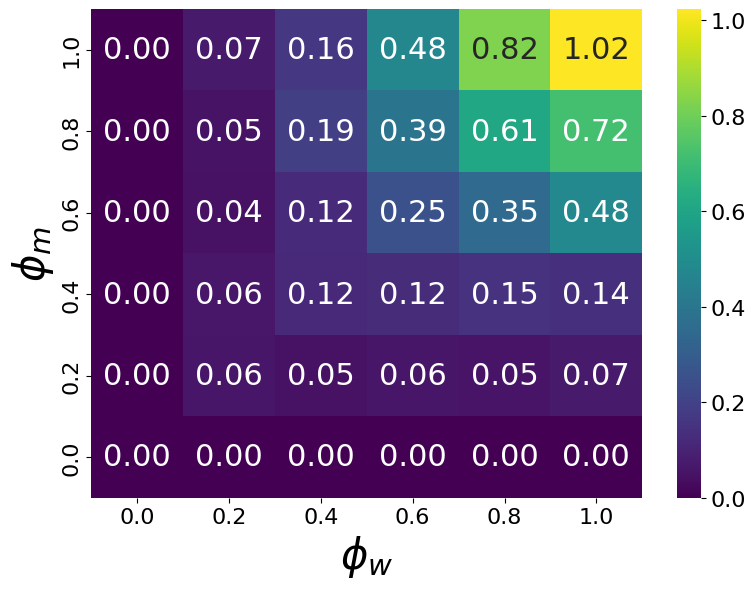

In [1]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_mall_new.pdf", format="pdf")
plt.show()


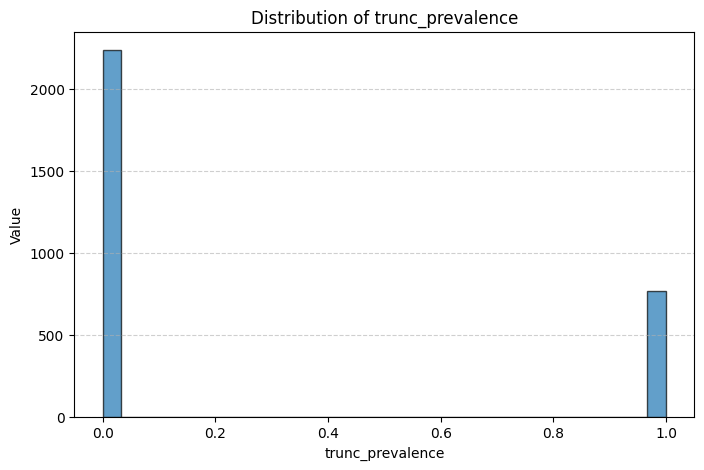

trunc_prevalence mean: 0.2547
trunc_prevalence median: 0.0000
trunc_prevalence max: 1.0000


In [35]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_prevalence"], bins=30, edgecolor="black", alpha=0.7)

plt.title("Distribution of trunc_prevalence")

plt.xlabel("trunc_prevalence")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_prevalence"].mean()

median_val = df["trunc_prevalence"].median()

max_val = df["trunc_prevalence"].max()
 
print(f"trunc_prevalence mean: {mean_val:.4f}")

print(f"trunc_prevalence median: {median_val:.4f}")

print(f"trunc_prevalence max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

#df = pd.read_csv("mallows_gain_with_rank_diff.csv")
 
# Filter only positive avg_self_benefit values

#positive_df = df[df["trunc_count"] > 0]
 
# Plot distribution for positive values

#plt.figure(figsize=(8, 5))

#plt.hist(positive_df["trunc_count"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

#plt.xlabel("trunc_count")

#plt.ylabel("Value")

#plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

#mean_pos = positive_df["trunc_count"].mean()

#median_pos = positive_df["trunc_count"].median()

#max_pos = positive_df["trunc_count"].max()
 
# Add vertical lines for mean, median, max

#plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

#plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

#plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
#plt.legend()

#plt.show()
 
#print(f"Mean of trunc_count: {mean_pos:.4f}")

#print(f"Median of trunc_count: {median_pos:.4f}")

#print(f"Max of trunc_count: {max_pos:.4f}")

 

In [ ]:
df = pd.read_csv("mallows_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)

cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_euclidean_gain_egal.csv", index=False)


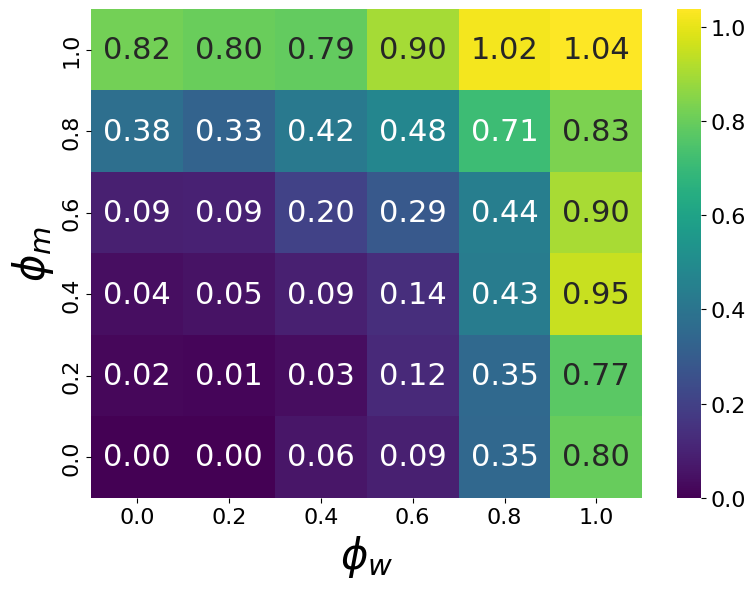

In [2]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_mall_euc_new.pdf", format="pdf")
plt.show()


3595     7
3596    10
3597    15
3598    20
3599     8
Name: trunc_egal, dtype: int64


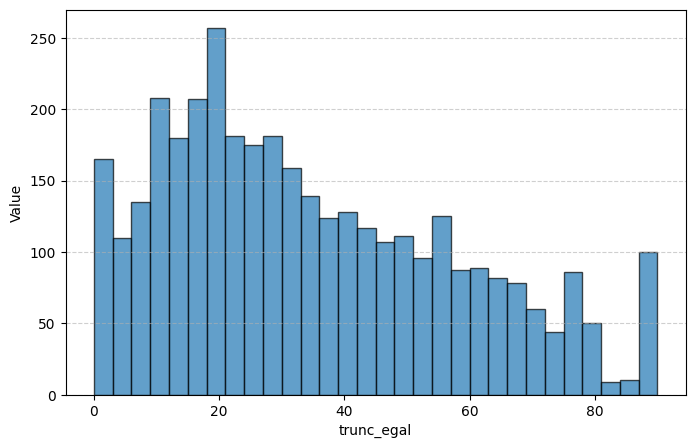

trunc_egal mean: 34.3308
trunc_egal median: 30.0000
trunc_egal max: 90.0000


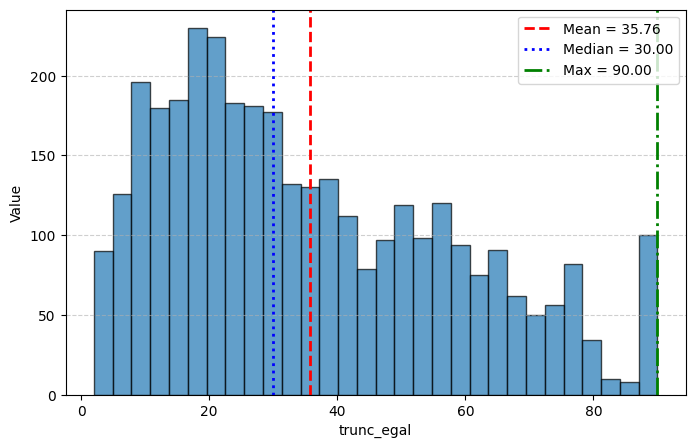

Mean of trunc_egal: 35.7613
Median of trunc_egal: 30.0000
Max of trunc_egal: 90.0000


In [2]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain_egal.csv")
print(df["trunc_egal"].tail())
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_egal"].mean()

median_val = df["trunc_egal"].median()

max_val = df["trunc_egal"].max()
 
print(f"trunc_egal mean: {mean_val:.4f}")

print(f"trunc_egal median: {median_val:.4f}")

print(f"trunc_egal max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain_egal.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["trunc_egal"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["trunc_egal"].mean()

median_pos = positive_df["trunc_egal"].median()

max_pos = positive_df["trunc_egal"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of trunc_egal: {mean_pos:.4f}")

print(f"Median of trunc_egal: {median_pos:.4f}")

print(f"Max of trunc_egal: {max_pos:.4f}")

 

In [40]:
df = pd.read_csv("mallows_MA_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_MA_gain_egal.csv", index=False)

cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_MA_gain_egal.csv", index=False)

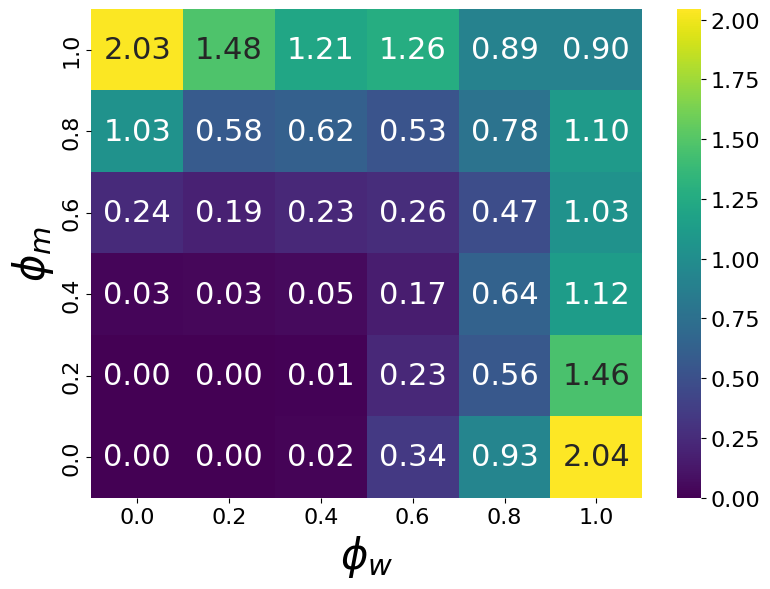

In [3]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MA_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_mall_MA_new.pdf", format="pdf")
plt.show()


3595    12
3596    12
3597     5
3598    22
3599     2
Name: trunc_egal, dtype: int64


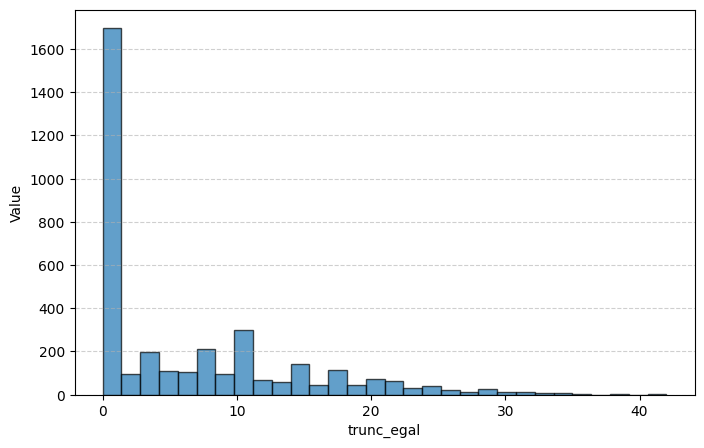

trunc_egal mean: 6.2358
trunc_egal median: 3.0000
trunc_egal max: 42.0000


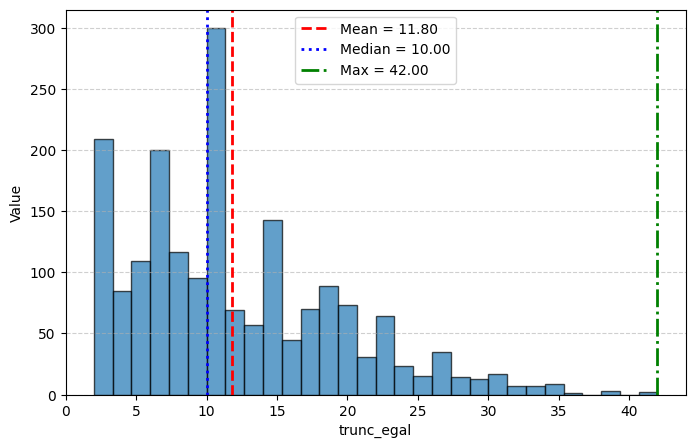

Mean of trunc_egal: 11.8028
Median of trunc_egal: 10.0000
Max of trunc_egal: 42.0000


In [3]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain_egal.csv")
print(df["trunc_egal"].tail())
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_egal"].mean()

median_val = df["trunc_egal"].median()

max_val = df["trunc_egal"].max()
 
print(f"trunc_egal mean: {mean_val:.4f}")

print(f"trunc_egal median: {median_val:.4f}")

print(f"trunc_egal max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain_egal.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["trunc_egal"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["trunc_egal"].mean()

median_pos = positive_df["trunc_egal"].median()

max_pos = positive_df["trunc_egal"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of trunc_egal: {mean_pos:.4f}")

print(f"Median of trunc_egal: {median_pos:.4f}")

print(f"Max of trunc_egal: {max_pos:.4f}")

 

In [42]:
df = pd.read_csv("mallows_MD_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("mallows_MD_gain_egal.csv", index=False)

cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("mallows_MD_gain_egal.csv", index=False)

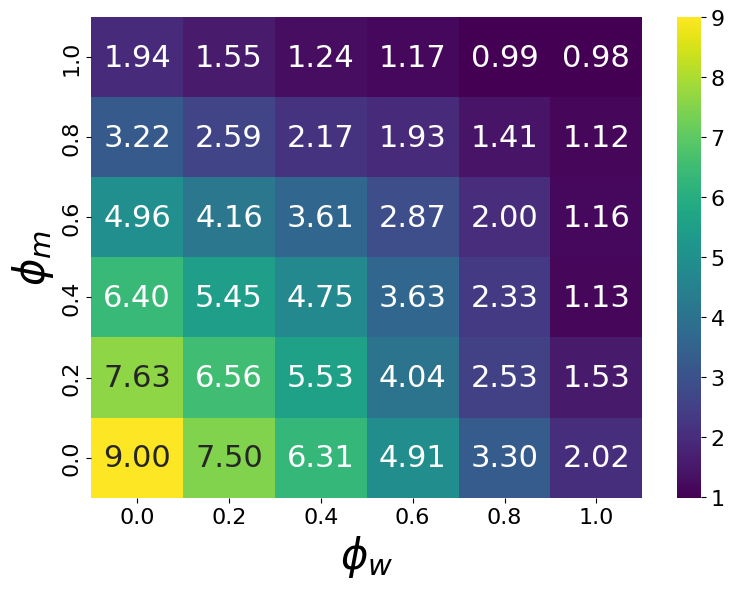

In [4]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_egal"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_mall_MD_new.pdf", format="pdf")
plt.show()


3595    17
3596     9
3597     4
3598    14
3599     0
Name: trunc_egal, dtype: int64


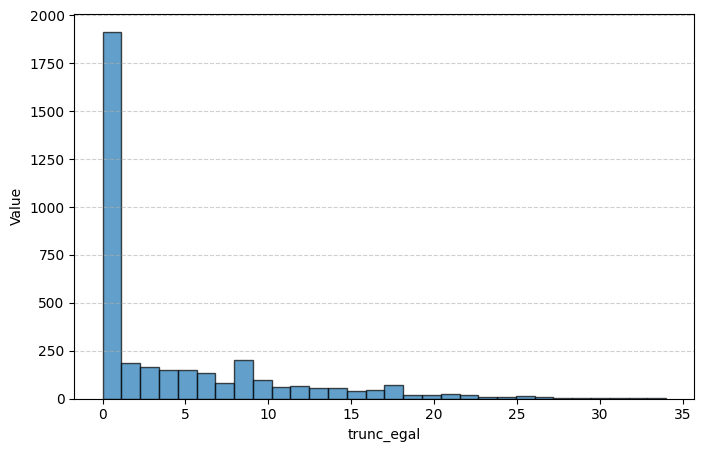

trunc_egal mean: 4.1186
trunc_egal median: 0.0000
trunc_egal max: 34.0000


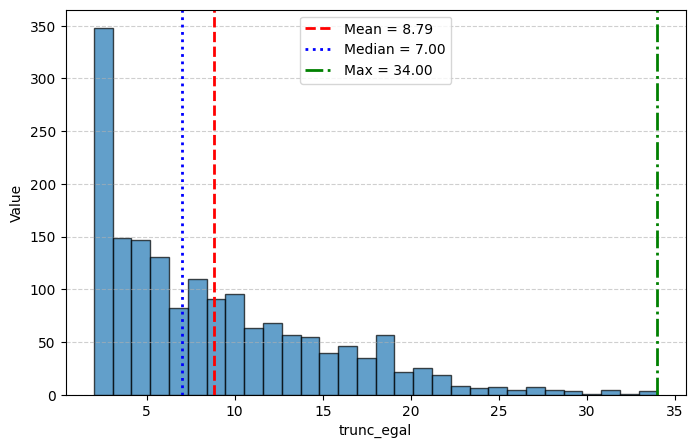

Mean of trunc_egal: 8.7942
Median of trunc_egal: 7.0000
Max of trunc_egal: 34.0000


In [4]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain_egal.csv")
print(df["trunc_egal"].tail())
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_egal"].mean()

median_val = df["trunc_egal"].median()

max_val = df["trunc_egal"].max()
 
print(f"trunc_egal mean: {mean_val:.4f}")

print(f"trunc_egal median: {median_val:.4f}")

print(f"trunc_egal max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain_egal.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["trunc_egal"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["trunc_egal"].mean()

median_pos = positive_df["trunc_egal"].median()

max_pos = positive_df["trunc_egal"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of trunc_egal: {mean_pos:.4f}")

print(f"Median of trunc_egal: {median_pos:.4f}")

print(f"Max of trunc_egal: {max_pos:.4f}")

 

In [44]:
df = pd.read_csv("reverse_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("reverse_euclidean_gain_egal.csv", index=False)

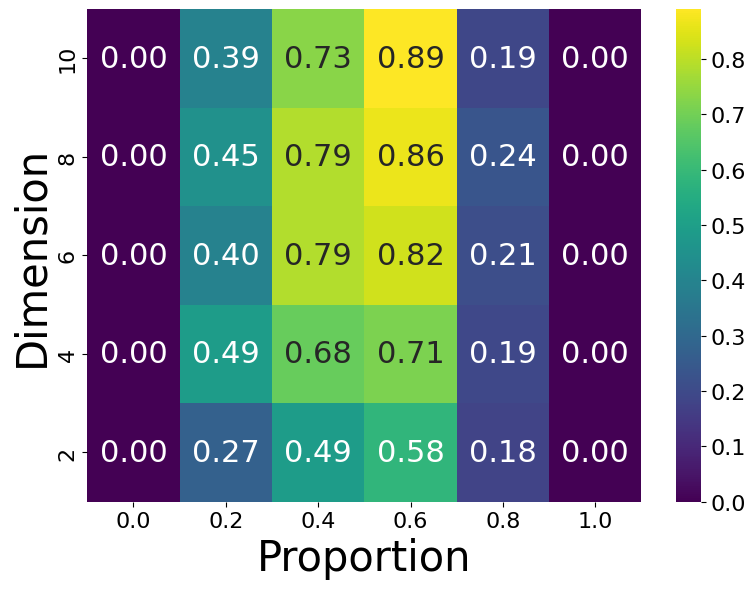

In [5]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain_egal.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["trunc_egal"].mean().reset_index()

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel("Proportion", fontsize=30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_rev_euc_new.pdf", format="pdf")
plt.show()


2995    0
2996    0
2997    0
2998    0
2999    0
Name: trunc_egal, dtype: int64


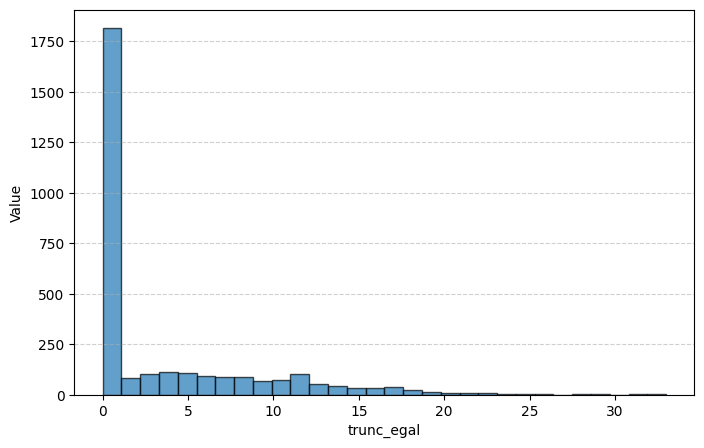

trunc_egal mean: 3.4520
trunc_egal median: 0.0000
trunc_egal max: 33.0000


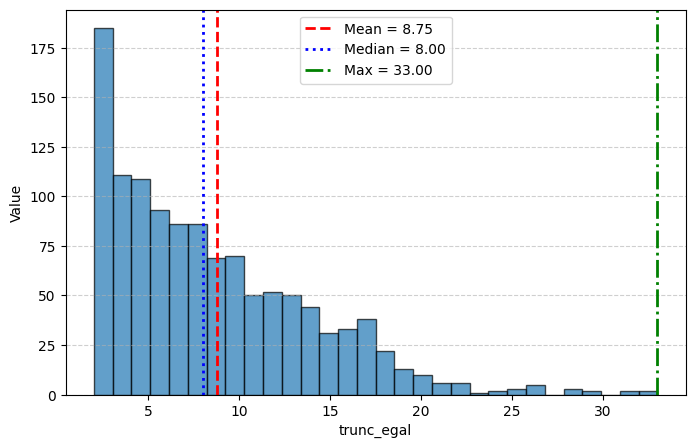

Mean of trunc_egal: 8.7466
Median of trunc_egal: 8.0000
Max of trunc_egal: 33.0000


In [5]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain_egal.csv")
print(df["trunc_egal"].tail())
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_egal"].mean()

median_val = df["trunc_egal"].median()

max_val = df["trunc_egal"].max()
 
print(f"trunc_egal mean: {mean_val:.4f}")

print(f"trunc_egal median: {median_val:.4f}")

print(f"trunc_egal max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain_egal.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["trunc_egal"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["trunc_egal"].mean()

median_pos = positive_df["trunc_egal"].median()

max_pos = positive_df["trunc_egal"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of trunc_egal: {mean_pos:.4f}")

print(f"Median of trunc_egal: {median_pos:.4f}")

print(f"Max of trunc_egal: {max_pos:.4f}")

 

In [46]:
df = pd.read_csv("expectations_euclidean_gain.csv")

egalitarian_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = egalitarian_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    egalitarian_matches.append(best_match)
df["egalitarian_match"] = egalitarian_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)

men_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = men_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    men_matches.append(best_match)
df["men_opt_match"] = men_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)


women_matches = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref

    stable = find_all_stable_original(mpref, wpref, len(mpref))
    best_match = None
    best_cost = float("inf")
    for match in stable:
        cost = women_cost(match, m_pref, w_pref)
        if cost < best_cost:
            best_cost = cost
            best_match = match

    women_matches.append(best_match)
df["women_opt_match"] = women_matches
df.to_csv("expectations_euclidean_gain.csv", index=False)

cost_diffs = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[]] + m_pref
    wpref = [[]] + w_pref
    
    stable = find_all_stable_original(mpref, wpref, len(mpref))

    egal = row["egalitarian_match"]  # <- no ast.literal_eval
    egal_cost = egalitarian_cost(egal, m_pref, w_pref)

    men_opt = row["men_opt_match"]
    men_cost1 = men_cost(men_opt, m_pref, w_pref)

    women_opt = row["women_opt_match"]
    women_cost1 = women_cost(women_opt, m_pref, w_pref)

    delta = egal_cost - men_cost1 - women_cost1
    cost_diffs.append(delta)



df["trunc_egal"] = cost_diffs
df.to_csv("expectations_euclidean_gain.csv", index=False)

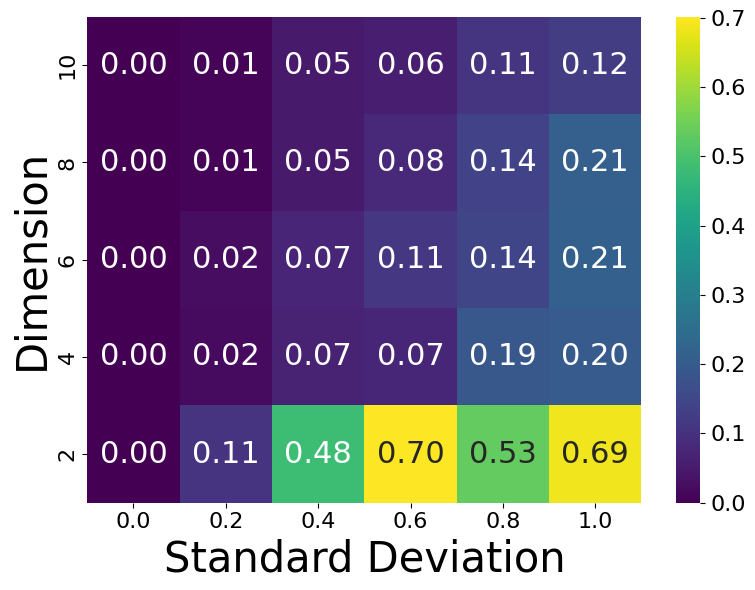

In [6]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain.csv")

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["trunc_egal"].mean().reset_index()

heatmap_data["trunc_egal"] = heatmap_data["trunc_egal"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="trunc_egal")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22})
#plt.title("Mallows")
plt.xlabel("Standard Deviation", fontsize=30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_egal_exp_euc_new.pdf", format="pdf")
plt.show()


2995    0
2996    2
2997    0
2998    2
2999    0
Name: trunc_egal, dtype: int64


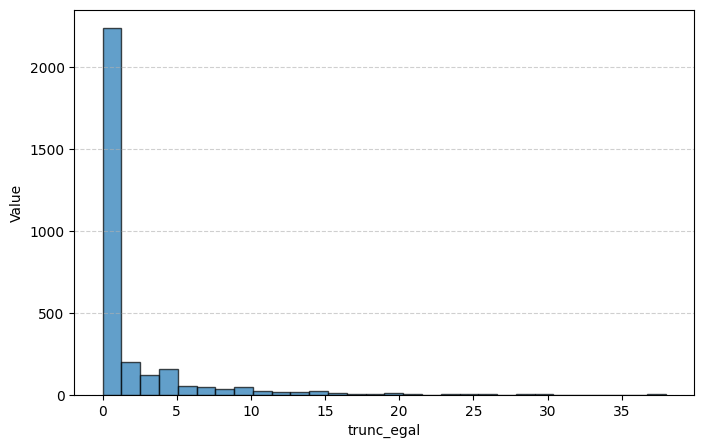

trunc_egal mean: 1.4860
trunc_egal median: 0.0000
trunc_egal max: 38.0000


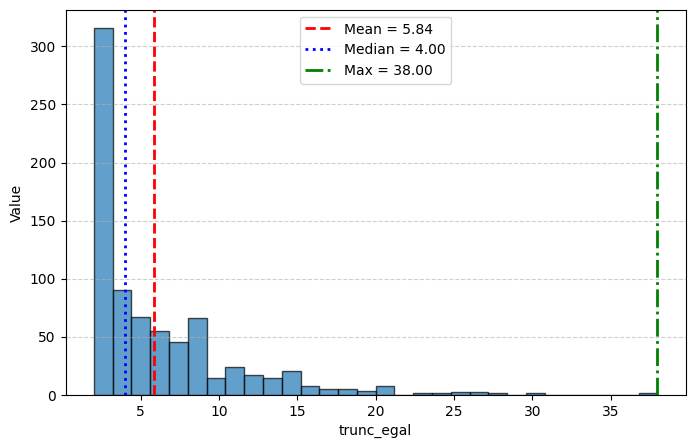

Mean of trunc_egal: 5.8351
Median of trunc_egal: 4.0000
Max of trunc_egal: 38.0000


In [6]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
print(df["trunc_egal"].tail())
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["trunc_egal"].mean()

median_val = df["trunc_egal"].median()

max_val = df["trunc_egal"].max()
 
print(f"trunc_egal mean: {mean_val:.4f}")

print(f"trunc_egal median: {median_val:.4f}")

print(f"trunc_egal max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["trunc_egal"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["trunc_egal"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("trunc_egal")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["trunc_egal"].mean()

median_pos = positive_df["trunc_egal"].median()

max_pos = positive_df["trunc_egal"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of trunc_egal: {mean_pos:.4f}")

print(f"Median of trunc_egal: {median_pos:.4f}")

print(f"Max of trunc_egal: {max_pos:.4f}")

 